In [19]:
# Project: Saudi Stock Price Prediction Using Linear Regression
# Idea: Predict Al Rajhi Bank's current closing stock price using information from the previous trading day
# Dataset: Saudi Stock Exchange (Tadawul) historical data --- filtered to Al Rajhi Bank (symbol 1120), covering 2001–2020
# Technique: Supervised Learning --- using Linear Regression
# Evaluation: MAE, MSE, RMSE, and R²

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Al_Rajhi_1120_clean.csv")
df.head()

,symbol,name,trading_name,sectoer,date,open,high,low,close,change,perc_Change,volume_traded,value_traded,no_trades
0,1120,Al Rajhi Bank,ALRAJHI,Financials,2020-03-05,61.7,61.7,60.6,61.0,-0.3,-0.49,8101466.0,495456693.0,NaN
1,1120,Al Rajhi Bank,ALRAJHI,Financials,2020-03-04,60.2,61.4,59.5,61.3,-0.4,-0.65,9326748.0,565967141.1,NaN
2,1120,Al Rajhi Bank,ALRAJHI,Financials,2020-03-03,61.0,61.8,60.6,61.7,2.0,3.35,8509603.0,520518756.5,NaN
3,1120,Al Rajhi Bank,ALRAJHI,Financials,2020-03-02,60.7,61.4,59.6,59.7,0.2,0.34,11089823.0,674338728.5,NaN
4,1120,Al Rajhi Bank,ALRAJHI,Financials,2020-03-01,60.0,60.5,58.7,59.5,-2.4,-3.88,10265006.0,612717230.4,NaN


## 1. Inspect the Dataset

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4758 entries, 0 to 4757
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   symbol         4758 non-null   int64  
 1   name           4758 non-null   object 
 2   trading_name   4758 non-null   object 
 3   sectoer        4758 non-null   object 
 4   date           4758 non-null   object 
 5   open           4758 non-null   float64
 6   high           4758 non-null   float64
 7   low            4758 non-null   float64
 8   close          4758 non-null   float64
 9   change         4758 non-null   float64
 10  perc_Change    4758 non-null   float64
 11  volume_traded  4758 non-null   float64
 12  value_traded   4758 non-null   float64
 13  no_trades      0 non-null      float64
dtypes: float64(9), int64(1), object(4)
memory usage: 520.5+ KB


In [21]:
df.isnull().sum()

symbol              0
name                0
trading_name        0
sectoer             0
date                0
open                0
high                0
low                 0
close               0
change              0
perc_Change         0
volume_traded       0
value_traded        0
no_trades        4758
dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

## 2. Data Preprocessing

In [23]:
# Remove the column that has missing values
df = df.drop(columns=["no_trades"])

# Converting data
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4758 entries, 0 to 4757
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   symbol         4758 non-null   int64         
 1   name           4758 non-null   object        
 2   trading_name   4758 non-null   object        
 3   sectoer        4758 non-null   object        
 4   date           4758 non-null   datetime64[ns]
 5   open           4758 non-null   float64       
 6   high           4758 non-null   float64       
 7   low            4758 non-null   float64       
 8   close          4758 non-null   float64       
 9   change         4758 non-null   float64       
 10  perc_Change    4758 non-null   float64       
 11  volume_traded  4758 non-null   float64       
 12  value_traded   4758 non-null   float64       
dtypes: datetime64[ns](1), float64(8), int64(1), object(3)
memory usage: 483.4+ KB


## 3. Exploratory Data Analysis (EDA)

In [6]:
df.describe()

,symbol,date,open,high,low,close,change,perc_Change,volume_traded,value_traded
count,4758.0,4758,4758.000000,4758.000000,4758.000000,4758.000000,4758.000000,4758.000000,4.758000e+03,4.758000e+03
mean,1120.0,2010-10-08 08:23:00.075662080,43.774197,44.287778,43.292247,43.791774,-0.132934,0.029714,3.643134e+06,1.746058e+08
min,1120.0,2001-12-31 00:00:00,10.210000,10.210000,10.210000,10.200000,-681.200000,-98.230000,6.052000e+03,1.836650e+05
25%,1120.0,2005-12-18 06:00:00,35.610000,35.930000,35.120000,35.570000,-0.290000,-0.650000,1.552809e+06,5.999400e+07
50%,1120.0,2010-08-16 12:00:00,43.090000,43.570000,42.760000,43.070000,0.000000,0.000000,2.788596e+06,1.182142e+08
75%,1120.0,2015-05-31 18:00:00,50.240000,51.050000,49.750000,50.412500,0.300000,0.710000,4.605666e+06,2.072291e+08
max,1120.0,2020-03-05 00:00:00,154.300000,154.300000,142.920000,148.290000,12.160000,10.130000,7.965946e+07,4.689544e+09
std,0.0,NaN,20.487769,20.903858,20.075834,20.485101,9.941560,2.316424,3.768008e+06,2.336920e+08


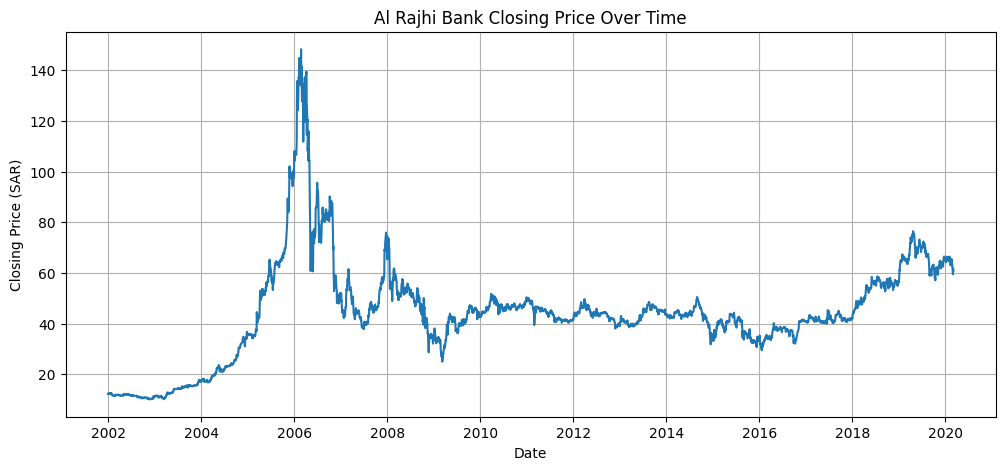

In [7]:
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["close"])
plt.title("Al Rajhi Bank Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price (SAR)")
plt.grid(True)
plt.show()

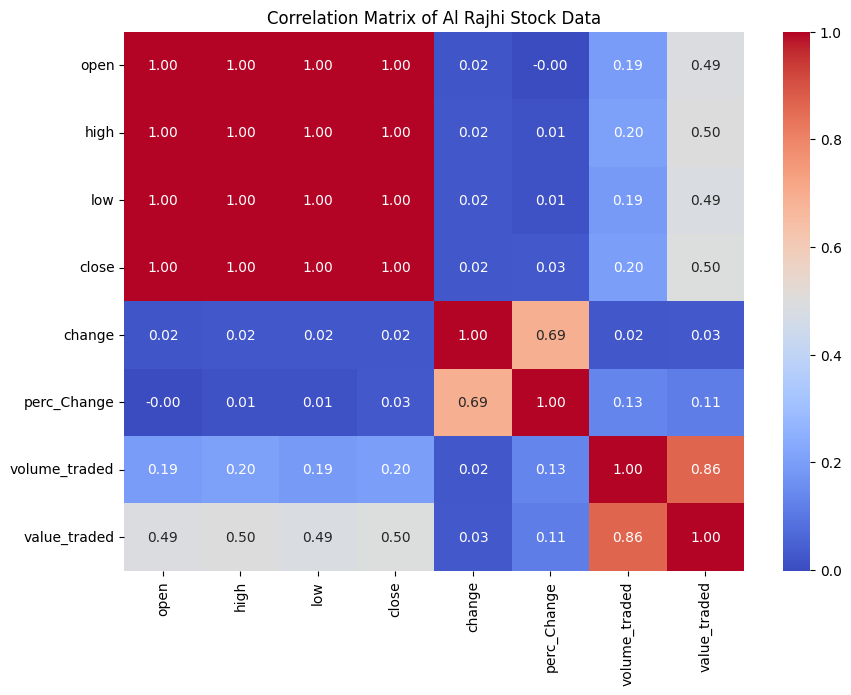

In [8]:
numeric_cols = [
    "open", "high", "low", "close", "change",
    "perc_Change", "volume_traded", "value_traded"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Al Rajhi Stock Data")
plt.show()

## 4. Feature Engineering

In [9]:
# Use previous information as input features
df["prev_open"] = df["open"].shift(1)
df["prev_high"] = df["high"].shift(1)
df["prev_low"] = df["low"].shift(1)
df["prev_close"] = df["close"].shift(1)
df["prev_volume"] = df["volume_traded"].shift(1)

# The first row has no previous trading day data, so remove it
df = df.dropna().reset_index(drop=True)

df.head()

,symbol,name,trading_name,sectoer,date,open,high,low,close,change,perc_Change,volume_traded,value_traded,prev_open,prev_high,prev_low,prev_close,prev_volume
0,1120,Al Rajhi Bank,ALRAJHI,Financials,2002-01-01,12.29,12.45,12.29,12.45,0.15,1.22,874641.0,10802558.00,12.62,12.62,12.29,12.30,1274457.0
1,1120,Al Rajhi Bank,ALRAJHI,Financials,2002-01-02,12.45,12.45,12.29,12.45,0.00,0.00,1147755.0,14185618.25,12.29,12.45,12.29,12.45,874641.0
2,1120,Al Rajhi Bank,ALRAJHI,Financials,2002-01-03,12.45,12.45,12.29,12.45,0.00,0.00,490650.0,6058139.75,12.45,12.45,12.29,12.45,1147755.0
3,1120,Al Rajhi Bank,ALRAJHI,Financials,2002-01-05,12.45,12.45,12.29,12.45,0.00,0.00,748828.0,9261847.50,12.45,12.45,12.29,12.45,490650.0
4,1120,Al Rajhi Bank,ALRAJHI,Financials,2002-01-06,12.45,12.45,12.45,12.45,0.00,0.00,563384.0,6978321.75,12.45,12.45,12.29,12.45,748828.0


In [10]:
# Check missing values 
df[[
    "prev_open", "prev_high", "prev_low",
    "prev_close", "prev_volume"
]].isnull().sum()

prev_open      0
prev_high      0
prev_low       0
prev_close     0
prev_volume    0
dtype: int64

## 5. Define Features and Target

In [11]:
X = df[
    [
        "prev_open",
        "prev_high",
        "prev_low",
        "prev_close",
        "prev_volume"
    ]
]

# Target: current day's closing price
y = df["close"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4757, 5)
Target shape: (4757,)


## 6. Train/Test Split

In [12]:
# first 80% for training, last 20% for testing
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape, y_train.shape)
print("Testing data:", X_test.shape, y_test.shape)

Training data: (3805, 5) (3805,)
Testing data: (952, 5) (952,)


## 7. Feature Scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (3805, 5)
X_test_scaled shape: (952, 5)


## 8. Train the Linear Regression Model

In [14]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Model training completed successfully")

Model training completed successfully


## 9. Make Predictions

In [15]:
y_pred = model.predict(X_test_scaled)
print(y_pred[:10])

[38.61037834 38.67020777 38.70180289 38.76953478 38.77296462 38.85218821
 38.80281694 38.40441019 37.8102517  36.82987062]


## 10. Evaluate the Model

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 0.4701061722237908
MSE : 0.4408671949129846
RMSE: 0.6639783090681386
R²  : 0.9966472373134426


## 11. Actual vs. Predicted Closing Prices

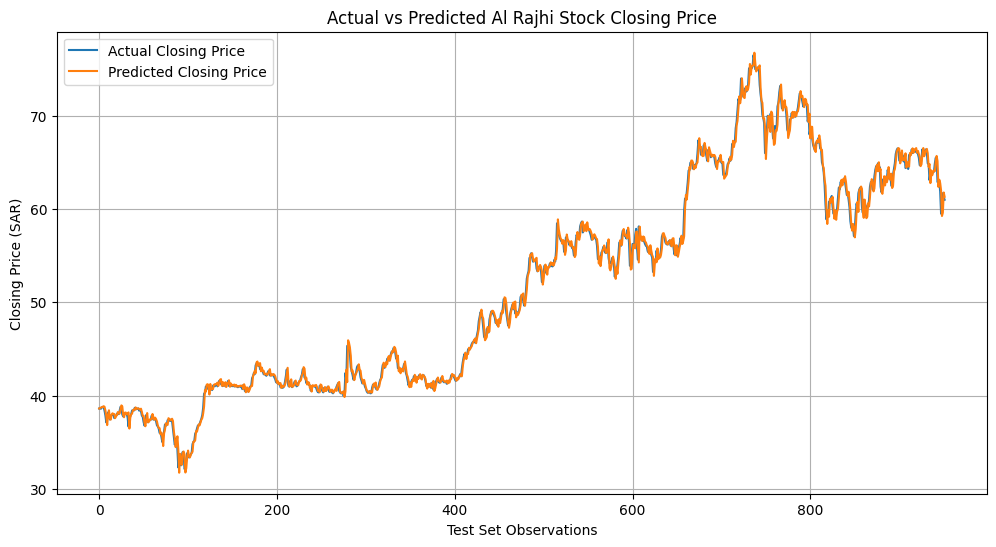

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label="Actual Closing Price")
plt.plot(y_pred, label="Predicted Closing Price")
plt.title("Actual vs Predicted Al Rajhi Stock Closing Price")
plt.xlabel("Test Set Observations")
plt.ylabel("Closing Price (SAR)")
plt.legend()
plt.grid(True)
plt.show()